In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv("exoplanet_data.csv", comment = "#")

In [3]:
print(df.shape)

(597, 92)


In [4]:
print(df.head)

<bound method NDFrame.head of          pl_name   hostname  default_flag  sy_snum  sy_pnum  discoverymethod  \
0        7 CMa c      7 CMa             1        1        2  Radial Velocity   
1        7 CMa c      7 CMa             0        1        2  Radial Velocity   
2       DMPP-1 b     DMPP-1             0        1        4  Radial Velocity   
3       DMPP-1 b     DMPP-1             1        1        4  Radial Velocity   
4       DMPP-1 c     DMPP-1             1        1        4  Radial Velocity   
..           ...        ...           ...      ...      ...              ...   
592    bet Pic c    bet Pic             0        1        3  Radial Velocity   
593  eps Ind A b  eps Ind A             0        3        1  Radial Velocity   
594  eps Ind A b  eps Ind A             0        3        1  Radial Velocity   
595  eps Ind A b  eps Ind A             1        3        1  Radial Velocity   
596  eps Ind A b  eps Ind A             0        3        1  Radial Velocity   

     disc

The data set is 597 rows by 92 columns



In [5]:
print(df.columns)

Index(['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum',
       'discoverymethod', 'disc_year', 'disc_facility', 'soltype',
       'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1',
       'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1',
       'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1',
       'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2',
       'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2',
       'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2',
       'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1',
       'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1',
       'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2',
       'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2

# Columns I have no clue what they mean
pl_controv_flag

pl_radeerr1

pl_orbsmaxerr2

sy_vmagerr1

sy_gaiamagerr1
(And many others)

In [6]:
df2 = pd.read_csv("exoplanet_data_trimmed.csv", comment = "#")

In [7]:
df2.head

<bound method NDFrame.head of          pl_name hostname  sy_snum  sy_pnum  discoverymethod  pl_bmassj  \
0       11 Com b   11 Com        2        1  Radial Velocity     15.464   
1       11 Com b   11 Com        2        1  Radial Velocity     17.100   
2       11 Com b   11 Com        2        1  Radial Velocity     19.400   
3       11 UMi b   11 UMi        1        1  Radial Velocity     14.740   
4       11 UMi b   11 UMi        1        1  Radial Velocity     10.800   
...          ...      ...      ...      ...              ...        ...   
40345  ups And d  ups And        2        3  Radial Velocity      4.132   
40346  ups Leo b  ups Leo        1        1  Radial Velocity      0.510   
40347   xi Aql b   xi Aql        1        1  Radial Velocity      2.800   
40348   xi Aql b   xi Aql        1        1  Radial Velocity      1.941   
40349   xi Aql b   xi Aql        1        1  Radial Velocity      2.020   

       pl_bmassjerr1  pl_bmassjerr2  pl_bmassjlim  pl_eqt  pl_eqterr1

# What does it mean?

Planet name: Name of the planet

Host Name: name of the star the exoplanet orbits

Discovery Method: Presumably which telescope?

Spectral Type: Star type, (e.g. OBAFGKM or non main line stars)

Equilibrium Temperature: What temp is the star

Planet mass or ...: Essentially either the mass of the planet or the mass of the inclined binary in terms of Jupiter's mass?

In [8]:
df3 = df[["pl_name", "hostname", "discoverymethod", "st_spectype", "pl_eqt", "pl_bmassj"]].copy()

In [9]:
df3 = df3.dropna()

In [10]:
print(df3.shape)

(75, 6)


There are 75 rows, and 6 columns.

In [11]:
print(df3.head)
print(df3.tail)

<bound method NDFrame.head of          pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
2       DMPP-1 b     DMPP-1  Radial Velocity        F8 V   877.0   0.076362
5       DMPP-1 c     DMPP-1  Radial Velocity        F8 V  1239.0   0.030205
7       DMPP-1 d     DMPP-1  Radial Velocity        F8 V  1632.0   0.010540
8       DMPP-1 e     DMPP-1  Radial Velocity        F8 V  1314.0   0.012994
10      DMPP-2 b     DMPP-2  Radial Velocity        F5 V  1000.0   0.437000
..           ...        ...              ...         ...     ...        ...
572   WASP-185 b   WASP-185          Transit        G0 V  1160.0   0.980000
576   WASP-190 b   WASP-190          Transit     F6 IV-V  1500.0   1.000000
581   WASP-192 b   WASP-192          Transit        G0 V  1620.0   2.300000
586       XO-7 b       XO-7          Transit        G0 V  1743.0   0.709000
593  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0   6.310000

[75 rows x 6 columns]>
<bound method NDFrame.tail of     

In [12]:
print(df3.columns)

Index(['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt',
       'pl_bmassj'],
      dtype='str')


In [13]:
print(df3["discoverymethod"].value_counts())

discoverymethod
Transit            60
Radial Velocity    13
Imaging             2
Name: count, dtype: int64


There is transit, radial velocity, and imaging as methods of discovery.

Transit: when a planet eclipses a star (60 instances)

Radial Velocity: When a planet orbits a star, it induces wobble which induces doppler shifting to the emission of the star, allowing discovery of a "dark companion" (13 instances)

Imaging: You see the planet, or directly observe it, through telescoping or radio (2 instances)

Transit is by far the most common, while imaging is by far the least common method.

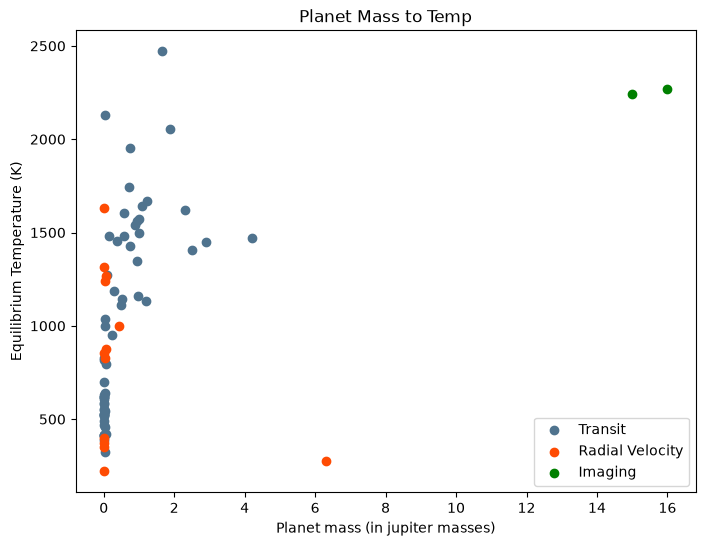

In [14]:
plt.figure(figsize =(8, 6))

transit_df = df3[df3["discoverymethod"] == "Transit"]
plt.scatter(transit_df["pl_bmassj"], transit_df["pl_eqt"], color = 'xkcd:metallic blue', label = "Transit")
rv_df = df3[df3["discoverymethod"] == "Radial Velocity"]
plt.scatter(rv_df["pl_bmassj"], rv_df["pl_eqt"], color = 'xkcd:blood orange', label = "Radial Velocity")
imaging_df = df3[df3["discoverymethod"] == "Imaging"]
plt.scatter(imaging_df["pl_bmassj"], imaging_df["pl_eqt"], color = 'green', label = "Imaging")

plt.legend()
plt.xlabel("Planet mass (in jupiter masses)")
plt.ylabel("Equilibrium Temperature (K)")
plt.title("Planet Mass to Temp")
plt.show()

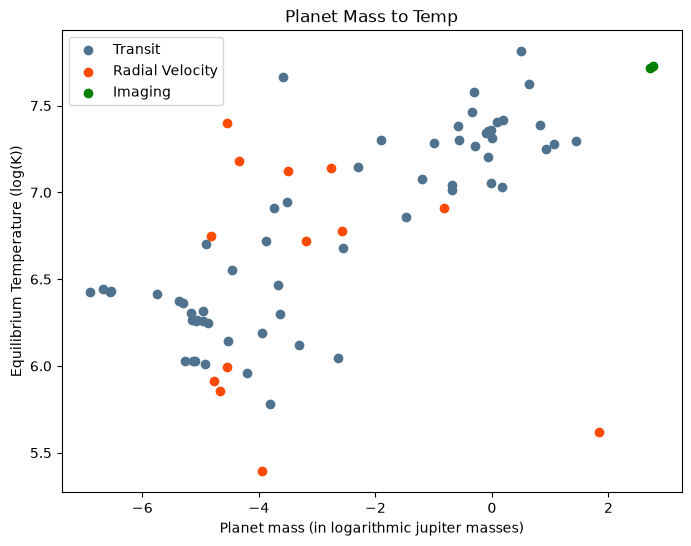

In [16]:
plt.figure(figsize =(8, 6))

transit_df = df3[df3["discoverymethod"] == "Transit"]
plt.scatter(np.log(transit_df["pl_bmassj"]), np.log(transit_df["pl_eqt"]), color = 'xkcd:metallic blue', label = "Transit")
rv_df = df3[df3["discoverymethod"] == "Radial Velocity"]
plt.scatter(np.log(rv_df["pl_bmassj"]), np.log(rv_df["pl_eqt"]), color = 'xkcd:blood orange', label = "Radial Velocity")
imaging_df = df3[df3["discoverymethod"] == "Imaging"]
plt.scatter(np.log(imaging_df["pl_bmassj"]), np.log(imaging_df["pl_eqt"]), color = 'green', label = "Imaging")

plt.legend()
plt.xlabel("Planet mass (in logarithmic jupiter masses)")
plt.ylabel("Equilibrium Temperature (log(K))")
plt.title("Planet Mass to Temp")
plt.show()

Planets found by imaging are more likely to be massive

In [38]:
bigger_5df = df3[df3["pl_bmassj"] > 5]
print(bigger_5df.loc[bigger_5df["pl_eqt"].idxmin()])


pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 593, dtype: object


The planets name is eps Ind A b

Index is 593 of all the stars above 5 Jupiter masses

Its equi temp is 275K

Its mass is 6.31 Jupiter masses

It's orbiting eps Ind A, which is a K5 star, which is not very close to the sun's spectral.

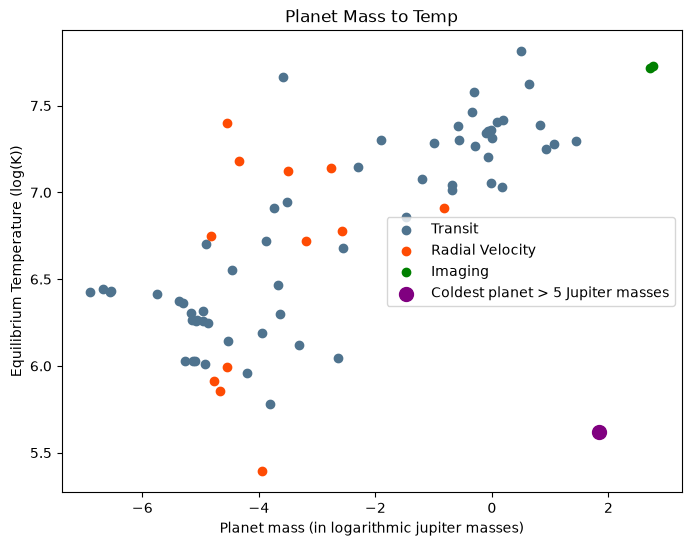

In [44]:
plt.figure(figsize =(8, 6))

transit_df = df3[df3["discoverymethod"] == "Transit"]
plt.scatter(np.log(transit_df["pl_bmassj"]), np.log(transit_df["pl_eqt"]), color = 'xkcd:metallic blue', label = "Transit")
rv_df = df3[df3["discoverymethod"] == "Radial Velocity"]
plt.scatter(np.log(rv_df["pl_bmassj"]), np.log(rv_df["pl_eqt"]), color = 'xkcd:blood orange', label = "Radial Velocity")
imaging_df = df3[df3["discoverymethod"] == "Imaging"]
plt.scatter(np.log(imaging_df["pl_bmassj"]), np.log(imaging_df["pl_eqt"]), color = 'green', label = "Imaging")

plt.scatter(np.log(6.31), np.log(275), color = "purple", s = 100, label = "Coldest planet > 5 Jupiter masses")

plt.legend()
plt.xlabel("Planet mass (in logarithmic jupiter masses)")
plt.ylabel("Equilibrium Temperature (log(K))")
plt.title("Planet Mass to Temp")
plt.show()

# A temperate super-Jupiter imaged with JWST in the mid-infrared

The abstract describes how we discovered a planet of large size and remarkably cold temp.

Yes, my answer matches

The planet is massive and yet incredibly cold for its size

The article lists temp as 275K (same as this data set) and size as 6.31 jupiter masses (same as this data set)